# 02. Modelagem e avaliação

**Objetivo:** treinar um classificador que estime, para cada pedido entregue, a probabilidade de o cliente dar nota 1 ou 2, e avaliar se ele é útil para o atendimento agir antes da avaliação.

Roteiro:
1. Divisão treino/teste estratificada.
2. Pré-processamento dentro de um `Pipeline` (evita vazamento entre treino e teste).
3. **Baseline:** Regressão Logística. **Modelo principal:** Random Forest.
4. Validação cruzada estratificada com 5 partes para comparar os dois.
5. Escolha do *threshold* (ponto de corte) e avaliação final no teste.
6. Importância das variáveis, análise de erros e limitações.
7. Salvar o modelo e as métricas usadas pelo app.

In [1]:
import sys, json, platform
from datetime import date
from pathlib import Path

RAIZ = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.metrics import (recall_score, precision_score, f1_score, accuracy_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             precision_recall_curve, roc_curve)

from src.config import (FEATURES, NUMERICAS, CATEGORICAS, ALVO, SEMENTE, MIN_PEDIDOS_CATEGORIA,
                        FAIXAS_RISCO, ARQ_MODELO, ARQ_METRICAS, ARQ_REFERENCIA, nome_categoria)
from src.preparacao import carregar_tabelas, montar_base
from src.graficos import aplicar_estilo, salvar, linha_taxa_base, AZUL, VERMELHO, CINZA

aplicar_estilo()
print("scikit-learn", sklearn.__version__)

scikit-learn 1.7.2


In [2]:
tabelas = carregar_tabelas()
base = montar_base(tabelas, verbose=False)
X = base[FEATURES]
y = base[ALVO]
print(f"{len(base):,} pedidos | {100 * y.mean():.1f}% negativos".replace(",", "."))
print("Variáveis:", FEATURES)

95.823 pedidos | 12.8% negativos
Variáveis: ['dias_atraso', 'tempo_entrega', 'valor_produtos', 'valor_frete', 'frete_sobre_valor', 'qtd_itens', 'parcelas', 'estados_diferentes', 'categoria', 'uf_cliente', 'uf_vendedor', 'pagamento']


## 1. Divisão treino/teste

- **80% treino, 20% teste.** O teste fica guardado e só é usado no final, para simular pedidos que o modelo nunca viu.
- **`stratify=y`**: mantém a mesma proporção de negativas (cerca de 12,8%) no treino e no teste. Sem isso, por azar, o teste poderia ter menos negativas e as métricas mudariam.
- **`random_state=42`**: semente fixa, para o resultado ser reproduzível por qualquer integrante.

In [3]:
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEMENTE)
idx_teste = X_teste.index  # guardamos os índices para a análise de erros
print(f"Treino: {len(X_treino):,} pedidos ({100 * y_treino.mean():.2f}% negativos)".replace(",", "."))
print(f"Teste:  {len(X_teste):,} pedidos ({100 * y_teste.mean():.2f}% negativos)".replace(",", "."))

Treino: 76.658 pedidos (12.81% negativos)
Teste:  19.165 pedidos (12.80% negativos)


## 2. Pré-processamento

O modelo só entende números. Usamos um `ColumnTransformer` para tratar cada tipo de coluna:

| Tipo | Passo | Por quê |
|---|---|---|
| Numéricas | `SimpleImputer(strategy="median")` | Segurança para valores ausentes em pedidos novos. A mediana não é puxada por extremos. |
| Numéricas (só Regressão Logística) | `StandardScaler()` | Coloca as variáveis na mesma escala (média 0, desvio 1). A Regressão Logística é sensível à escala; a Random Forest não precisa. |
| Categóricas | `OneHotEncoder(min_frequency=300, handle_unknown="infrequent_if_exist")` | Cria uma coluna 0/1 para cada categoria. Categorias com menos de 300 pedidos no treino viram um grupo "raras", para o modelo não decorar casos com poucos exemplos. Uma categoria nunca vista também cai nesse grupo, em vez de dar erro. |

Tudo fica dentro de um **`Pipeline`**: o pré-processamento é ajustado **só com os dados de treino** de cada etapa. Se calculássemos a mediana ou as categorias com a base inteira, informação do teste vazaria para o treino.

In [4]:
def criar_preprocessador(padronizar: bool):
    passos_num = [("imputar", SimpleImputer(strategy="median"))]
    if padronizar:
        passos_num.append(("padronizar", StandardScaler()))
    return ColumnTransformer([
        ("num", Pipeline(passos_num), NUMERICAS),
        ("cat", Pipeline([
            ("imputar", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(min_frequency=MIN_PEDIDOS_CATEGORIA,
                                     handle_unknown="infrequent_if_exist",
                                     sparse_output=False)),
        ]), CATEGORICAS),
    ])

## 3. Modelos

### 3.1 Baseline: Regressão Logística

O **baseline** é um modelo simples que serve de régua: o modelo principal só vale a pena se for melhor que ele.
A Regressão Logística calcula uma soma ponderada das variáveis e transforma em probabilidade com a função sigmoide. É rápida e fácil de interpretar (cada coeficiente diz se a variável aumenta ou diminui a chance), mas só captura relações **lineares**: "quanto mais atraso, mais risco, sempre na mesma proporção".

- `max_iter=2000`: número máximo de iterações do otimizador, alto o suficiente para convergir.
- `C=1.0`: força da regularização (padrão). Valores menores deixam os coeficientes mais "contidos".

### 3.2 Modelo principal: Random Forest

A **Random Forest** treina muitas árvores de decisão, cada uma com uma amostra diferente dos pedidos e das variáveis, e tira a média das respostas. Árvores capturam **relações não lineares e combinações**, por exemplo "atraso só pesa a partir de 1 dia" ou "atraso + vários itens".

- `n_estimators=200`: número de árvores. Mais árvores estabilizam o resultado; acima de ~200 o ganho é pequeno e o arquivo fica maior.
- `min_samples_leaf`: mínimo de pedidos em cada folha. Evita folhas com 1 ou 2 pedidos (decoreba, ou *overfitting*) e deixa as probabilidades mais estáveis. Escolhido por validação cruzada abaixo.
- `max_features="sqrt"`: cada divisão sorteia só parte das variáveis, o que deixa as árvores diferentes entre si.
- `n_jobs=-1`: usa todos os núcleos do processador.

### 3.3 Por que NÃO usamos `class_weight="balanced"`

Pesar as classes aumenta artificialmente a probabilidade da classe minoritária. O app mostra a **probabilidade** para o atendimento ("68% de chance"), então ela precisa ser realista. Tratamos o desbalanceamento de outro jeito: **escolhendo o threshold** (seção 5) em vez de usar o corte padrão de 50%.

In [5]:
baseline = Pipeline([
    ("prep", criar_preprocessador(padronizar=True)),
    ("modelo", LogisticRegression(max_iter=2000, C=1.0)),
])

random_forest = Pipeline([
    ("prep", criar_preprocessador(padronizar=False)),
    ("modelo", RandomForestClassifier(n_estimators=200, max_features="sqrt", min_samples_leaf=25,
                                      n_jobs=-1, random_state=SEMENTE)),
])

## 4. Validação cruzada estratificada

Em vez de confiar em uma única divisão, a **validação cruzada com 5 partes** (`StratifiedKFold`) divide o treino em 5 pedaços com a mesma proporção de negativas. Treina em 4 e avalia no 5º, repetindo 5 vezes. A média mostra o desempenho esperado e o desvio padrão mostra se ele é estável.

Métricas que **não dependem do threshold**:
- **ROC-AUC**: chance de o modelo dar probabilidade maior a um pedido negativo do que a um positivo sorteados ao acaso. 0,5 = chute, 1,0 = perfeito.
- **PR-AUC** (*average precision*): resume a curva precisão x recall. É mais exigente quando a classe de interesse é rara. Um chute teria PR-AUC igual à taxa de negativas (~0,13).

### 4.1 Ajuste do `min_samples_leaf` da Random Forest
Testamos alguns valores com `GridSearchCV`, otimizando a PR-AUC. Quando as diferenças são menores que a variação entre as partes da validação cruzada, não faz sentido escolher o "campeão" por uma casa decimal: usamos a **regra de um erro padrão** e ficamos com o modelo mais simples dentro dessa margem. Árvores com folhas maiores generalizam melhor, dão probabilidades mais estáveis e deixam o arquivo do modelo menor (importante para publicar o app).

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)

busca = GridSearchCV(
    random_forest,
    param_grid={"modelo__min_samples_leaf": [5, 25, 50, 100]},
    scoring="average_precision", cv=cv, n_jobs=1)
busca.fit(X_treino, y_treino)

resultado_busca = pd.DataFrame(busca.cv_results_)[["param_modelo__min_samples_leaf", "mean_test_score", "std_test_score"]]
resultado_busca.columns = ["min_samples_leaf", "PR-AUC média", "desvio"]
resultado_busca["erro_padrao"] = resultado_busca["desvio"] / np.sqrt(cv.get_n_splits())

# Regra de "um erro padrão": entre os valores cuja PR-AUC fica a menos de 1 erro padrão do melhor,
# escolhemos o MAIS SIMPLES (maior min_samples_leaf = árvores menores, modelo mais leve e estável).
melhor = resultado_busca.loc[resultado_busca["PR-AUC média"].idxmax()]
limite = melhor["PR-AUC média"] - melhor["erro_padrao"]
escolhido = int(resultado_busca.loc[resultado_busca["PR-AUC média"] >= limite, "min_samples_leaf"].max())
parametros_escolhidos = {"modelo__min_samples_leaf": escolhido}
print(f"Maior PR-AUC: min_samples_leaf={int(melhor['min_samples_leaf'])} ({melhor['PR-AUC média']:.4f})")
print(f"Limite (melhor - 1 erro padrão): {limite:.4f}")
print(f"Escolhido pela regra de 1 erro padrão: min_samples_leaf={escolhido}")
resultado_busca.round(4)

Maior PR-AUC: min_samples_leaf=5 (0.4666)
Limite (melhor - 1 erro padrão): 0.4599
Escolhido pela regra de 1 erro padrão: min_samples_leaf=100


,min_samples_leaf,PR-AUC média,desvio,erro_padrao
0,5,0.4666,0.0151,0.0068
1,25,0.4665,0.0159,0.0071
2,50,0.4645,0.0165,0.0074
3,100,0.4611,0.0152,0.0068


In [7]:
random_forest.set_params(**parametros_escolhidos)

comparacao = {}
for nome, modelo in [("Regressão Logística (baseline)", baseline), ("Random Forest", random_forest)]:
    r = cross_validate(modelo, X_treino, y_treino, cv=cv, scoring=["roc_auc", "average_precision"], n_jobs=1)
    comparacao[nome] = {
        "ROC-AUC": f"{r['test_roc_auc'].mean():.3f} ± {r['test_roc_auc'].std():.3f}",
        "PR-AUC": f"{r['test_average_precision'].mean():.3f} ± {r['test_average_precision'].std():.3f}",
        "_roc": r["test_roc_auc"].mean(), "_pr": r["test_average_precision"].mean(),
    }
tabela_cv = pd.DataFrame(comparacao).T
tabela_cv[["ROC-AUC", "PR-AUC"]]

,ROC-AUC,PR-AUC
Regressão Logística (baseline),0.734 ± 0.008,0.404 ± 0.011
Random Forest,0.755 ± 0.009,0.461 ± 0.015


**Leitura.** A Random Forest é melhor que o baseline nas duas métricas (ROC-AUC 0,755 contra 0,734; PR-AUC 0,461 contra 0,404). O desvio entre as 5 partes é pequeno (cerca de 0,01), então a diferença não depende da sorte de uma divisão. Os dois estão bem acima de um chute (PR-AUC 0,128).

## 5. Escolha do threshold

O modelo devolve uma probabilidade. Para virar um **alerta** (sim/não), precisamos de um ponto de corte:
se a probabilidade passar do threshold, o pedido entra na lista do atendimento.

- Threshold **baixo**: mais alertas, pega mais clientes insatisfeitos (**recall** alto), mas com mais alarmes falsos (**precisão** baixa).
- Threshold **alto**: menos alertas e mais certeiros, mas deixa passar mais insatisfeitos.

O corte padrão de 50% não serve aqui: com só 12,8% de negativas, o modelo raramente passa de 50% e deixaria passar a maioria dos insatisfeitos.

**Como escolhemos.** Usamos as previsões da validação cruzada no **treino** (`cross_val_predict`), nunca o teste, para não "ajustar a prova". Escolhemos o threshold que **maximiza o F1** (equilíbrio entre recall e precisão). Fazemos o mesmo para o baseline, para a comparação ser justa.

In [8]:
def escolher_threshold(y_true, prob):
    precisao, recall, cortes = precision_recall_curve(y_true, prob)
    f1 = 2 * precisao * recall / np.clip(precisao + recall, 1e-9, None)
    i = np.nanargmax(f1[:-1])  # o último ponto da curva não tem threshold associado
    return float(cortes[i]), pd.DataFrame({"threshold": cortes, "precisao": precisao[:-1],
                                           "recall": recall[:-1], "f1": f1[:-1]})

oof_rf = cross_val_predict(random_forest, X_treino, y_treino, cv=cv, method="predict_proba")[:, 1]
oof_lr = cross_val_predict(baseline, X_treino, y_treino, cv=cv, method="predict_proba")[:, 1]

threshold_rf, curva_rf = escolher_threshold(y_treino, oof_rf)
threshold_lr, curva_lr = escolher_threshold(y_treino, oof_lr)
print(f"Threshold Random Forest: {threshold_rf:.3f}")
print(f"Threshold Regressão Logística: {threshold_lr:.3f}")

Threshold Random Forest: 0.216
Threshold Regressão Logística: 0.218


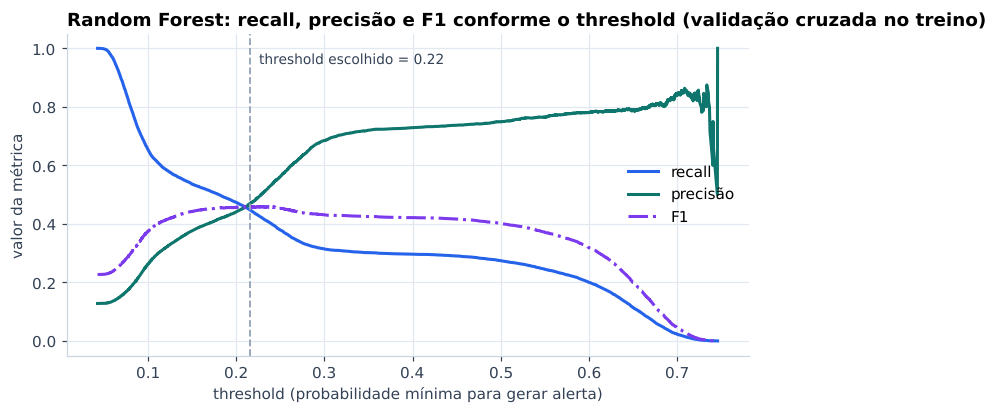

,recall mínimo,threshold,precisão,F1,% pedidos com alerta
0,0.3,0.361,0.723,0.424,5.313
1,0.4,0.240,0.535,0.458,9.583
2,0.5,0.180,0.416,0.454,15.376
3,0.6,0.115,0.307,0.406,25.007
4,0.7,0.093,0.232,0.349,38.591


In [9]:
fig, ax = plt.subplots(figsize=(8, 3.8))
c = curva_rf[curva_rf["threshold"] <= 0.9]
ax.plot(c["threshold"], c["recall"], color=AZUL, lw=2, label="recall")
ax.plot(c["threshold"], c["precisao"], color="#0f766e", lw=2, label="precisão")
ax.plot(c["threshold"], c["f1"], color="#7c3aed", lw=2, ls="-.", label="F1")
ax.axvline(threshold_rf, color=CINZA, ls="--", lw=1.2)
ax.annotate(f"threshold escolhido = {threshold_rf:.2f}", xy=(threshold_rf, 0.95), xytext=(6, 0),
            textcoords="offset points", fontsize=9, color="#334155")
ax.set_xlabel("threshold (probabilidade mínima para gerar alerta)")
ax.set_ylabel("valor da métrica")
ax.set_title("Random Forest: recall, precisão e F1 conforme o threshold (validação cruzada no treino)")
ax.legend(loc="center right")
salvar(fig, "07_threshold.png")
plt.show()

# Alternativas para discutir com o negócio: quanto de precisão custa cada nível de recall
alternativas = []
for r_alvo in [0.30, 0.40, 0.50, 0.60, 0.70]:
    linha = curva_rf[curva_rf["recall"] >= r_alvo].iloc[-1]
    alternativas.append({"recall mínimo": r_alvo, "threshold": linha["threshold"],
                         "precisão": linha["precisao"], "F1": linha["f1"],
                         "% pedidos com alerta": 100 * (oof_rf >= linha["threshold"]).mean()})
pd.DataFrame(alternativas).round(3)

**Leitura.** O F1 máximo fica no threshold de **0,22 (22%)**. Com esse corte, o modelo alerta cerca de 12% dos pedidos. A tabela mostra o custo de pedir mais recall: para pegar 60% dos insatisfeitos seria preciso alertar 25% dos pedidos, com precisão de 31% (cerca de 7 em cada 10 alertas seriam à toa). Se o atendimento tiver mais capacidade, dá para baixar o threshold. Essa é uma decisão de negócio, e o modelo permite ajustá-la sem retreinar.

## 6. Avaliação final no conjunto de teste

Agora treinamos os dois modelos com **todo o treino** e avaliamos **uma única vez** no teste.
Incluímos um "modelo ingênuo" que sempre responde "não negativa", só para mostrar por que a **acurácia** não serve.

| Métrica | O que significa neste problema |
|---|---|
| **Recall** | Dos clientes que deram nota 1 ou 2, quantos o modelo alertou. |
| **Precisão** | Dos alertas gerados, quantos eram mesmo clientes insatisfeitos. |
| **F1** | Média harmônica entre recall e precisão. |
| **ROC-AUC / PR-AUC** | Qualidade da ordenação por risco, sem depender do threshold. |

In [10]:
baseline.fit(X_treino, y_treino)
random_forest.fit(X_treino, y_treino)

prob_lr = baseline.predict_proba(X_teste)[:, 1]
prob_rf = random_forest.predict_proba(X_teste)[:, 1]

def metricas(y_true, prob, thr):
    pred = (prob >= thr).astype(int)
    return {"recall": recall_score(y_true, pred), "precisao": precision_score(y_true, pred, zero_division=0),
            "f1": f1_score(y_true, pred), "roc_auc": roc_auc_score(y_true, prob),
            "pr_auc": average_precision_score(y_true, prob), "acuracia": accuracy_score(y_true, pred),
            "threshold": thr, "perc_alertas": float(pred.mean())}

m_rf = metricas(y_teste, prob_rf, threshold_rf)
m_lr = metricas(y_teste, prob_lr, threshold_lr)
m_ing = metricas(y_teste, np.zeros(len(y_teste)), 0.5)
m_ing["roc_auc"], m_ing["pr_auc"] = 0.5, float(y_teste.mean())

tabela = pd.DataFrame({"Modelo ingênuo (sempre 'não')": m_ing, "Regressão Logística (baseline)": m_lr,
                       "Random Forest": m_rf}).T
tabela = tabela[["recall", "precisao", "f1", "roc_auc", "pr_auc", "acuracia", "threshold", "perc_alertas"]]
tabela.round(3)

,recall,precisao,f1,roc_auc,pr_auc,acuracia,threshold,perc_alertas
Modelo ingênuo (sempre 'não'),0.000,0.000,0.000,0.500,0.128,0.872,0.500,0.000
Regressão Logística (baseline),0.404,0.429,0.416,0.736,0.395,0.855,0.218,0.121
Random Forest,0.443,0.458,0.450,0.759,0.461,0.861,0.216,0.124


**Leitura.** No teste, a Random Forest encontra **44% dos clientes que deram nota 1 ou 2** (recall 0,443) e, de cada 100 alertas, **cerca de 46 são clientes realmente insatisfeitos** (precisão 0,458). O baseline fica abaixo em todas as métricas (F1 0,416 contra 0,450; PR-AUC 0,395 contra 0,461). Os números do teste estão próximos dos da validação cruzada, sinal de que não houve overfitting.

Repare que o modelo ingênuo tem **acurácia maior** (87,2%) que a Random Forest (86,1%) sem encontrar nenhum insatisfeito. É a prova de que acurácia não serve aqui. Outra comparação útil: alertar 12% dos pedidos ao acaso encontraria só 12% dos insatisfeitos; o modelo encontra 44%.

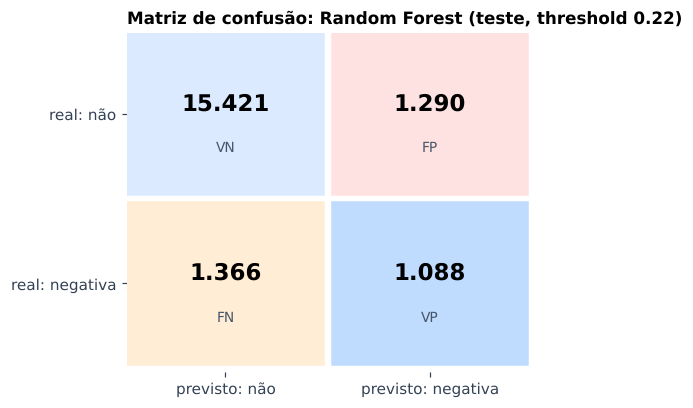

VN=15421  FP=1290  FN=1366  VP=1088


In [11]:
mc = confusion_matrix(y_teste, (prob_rf >= threshold_rf).astype(int))
vn, fp, fn, vp = mc.ravel()

fig, ax = plt.subplots(figsize=(4.8, 4))
cores = np.array([["#dbeafe", "#fee2e2"], ["#ffedd5", "#bfdbfe"]])
nomes = np.array([["VN", "FP"], ["FN", "VP"]])
for i in range(2):
    for j in range(2):
        ax.add_patch(plt.Rectangle((j, i), 0.96, 0.96, color=cores[i, j]))
        ax.text(j + 0.48, i + 0.42, f"{mc[i, j]:,}".replace(",", "."), ha="center", va="center", fontsize=15, fontweight="bold")
        ax.text(j + 0.48, i + 0.68, nomes[i, j], ha="center", va="center", fontsize=9, color="#475569")
ax.set_xlim(0, 2); ax.set_ylim(2, 0)
ax.set_xticks([0.48, 1.48], ["previsto: não", "previsto: negativa"])
ax.set_yticks([0.48, 1.48], ["real: não", "real: negativa"])
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_title(f"Matriz de confusão: Random Forest (teste, threshold {threshold_rf:.2f})", fontsize=11)
salvar(fig, "08_matriz_confusao.png")
plt.show()
print(f"VN={vn}  FP={fp}  FN={fn}  VP={vp}")

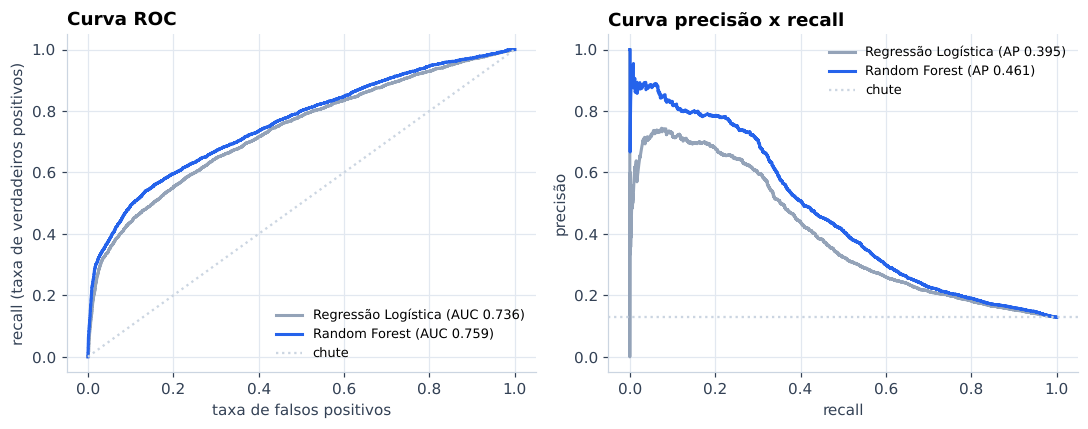

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for nome, prob, cor in [("Regressão Logística", prob_lr, CINZA), ("Random Forest", prob_rf, AZUL)]:
    fpr, tpr, _ = roc_curve(y_teste, prob)
    axes[0].plot(fpr, tpr, color=cor, lw=2, label=f"{nome} (AUC {roc_auc_score(y_teste, prob):.3f})")
    p, r, _ = precision_recall_curve(y_teste, prob)
    axes[1].plot(r, p, color=cor, lw=2, label=f"{nome} (AP {average_precision_score(y_teste, prob):.3f})")
axes[0].plot([0, 1], [0, 1], color="#cbd5e1", ls=":", label="chute")
axes[1].axhline(y_teste.mean(), color="#cbd5e1", ls=":", label="chute")
axes[0].set(title="Curva ROC", xlabel="taxa de falsos positivos", ylabel="recall (taxa de verdadeiros positivos)")
axes[1].set(title="Curva precisão x recall", xlabel="recall", ylabel="precisão")
for ax in axes:
    ax.legend(loc="lower right" if ax is axes[0] else "upper right", fontsize=8.5)
fig.tight_layout()
salvar(fig, "09_curvas_roc_pr.png")
plt.show()

## 7. As probabilidades são confiáveis? Faixas de risco do app

O app mostra a probabilidade e uma faixa (baixo < 15%, moderado 15 a 30%, alto 30 a 50%, muito alto ≥ 50%).
Conferimos duas coisas no teste:
1. **Calibração**: entre os pedidos com probabilidade perto de 40%, cerca de 40% foram mesmo negativos?
2. **Faixas**: quantos pedidos caem em cada faixa e qual a taxa real de negativas em cada uma.

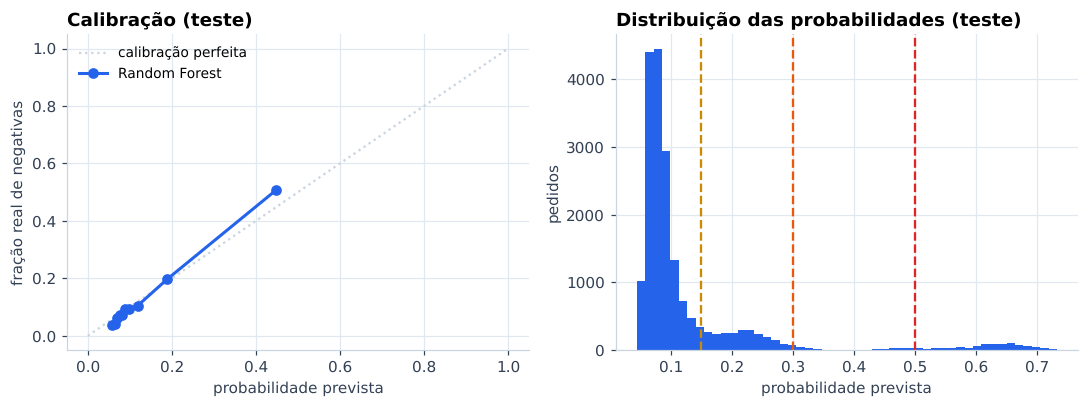

,pedidos,taxa_real,perc_pedidos
faixa,,,
Risco baixo,15548,7.2,81.1
Risco moderado,2449,22.5,12.8
Risco alto,283,44.2,1.5
Risco muito alto,885,73.6,4.6


In [13]:
frac_real, prob_media = calibration_curve(y_teste, prob_rf, n_bins=10, strategy="quantile")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].plot([0, 1], [0, 1], color="#cbd5e1", ls=":", label="calibração perfeita")
axes[0].plot(prob_media, frac_real, color=AZUL, marker="o", lw=2, label="Random Forest")
axes[0].set(title="Calibração (teste)", xlabel="probabilidade prevista", ylabel="fração real de negativas")
axes[0].legend(loc="upper left", fontsize=9)
axes[1].hist(prob_rf, bins=50, color=AZUL)
for lim, nome, cor, _ in FAIXAS_RISCO[1:]:
    axes[1].axvline(lim, color=cor, ls="--", lw=1.5)
axes[1].set(title="Distribuição das probabilidades (teste)", xlabel="probabilidade prevista", ylabel="pedidos")
fig.tight_layout()
salvar(fig, "10_calibracao_faixas.png")
plt.show()

limites = [f[0] for f in FAIXAS_RISCO] + [1.01]
nomes_faixa = [f[1] for f in FAIXAS_RISCO]
faixa_teste = pd.cut(prob_rf, bins=limites, labels=nomes_faixa, right=False)
tabela_faixas = pd.DataFrame({"faixa": faixa_teste, "negativa": y_teste.values}).groupby("faixa", observed=False).agg(
    pedidos=("negativa", "size"), taxa_real=("negativa", "mean"))
tabela_faixas["perc_pedidos"] = 100 * tabela_faixas["pedidos"] / len(y_teste)
tabela_faixas["taxa_real"] *= 100
tabela_faixas.round(1)

**Leitura.** As probabilidades estão **bem calibradas** (pontos perto da diagonal), então podem ser mostradas no app como uma chance real. As faixas do protótipo funcionam com a distribuição real e foram **mantidas**: a taxa real de negativas cresce de uma faixa para a outra e cai dentro dos limites de cada uma (7,2% no risco baixo, 22,5% no moderado, 44,2% no alto e 73,6% no muito alto). 81% dos pedidos ficam em risco baixo, então o atendimento só precisa olhar para cerca de 1 em cada 5 pedidos. O histograma mostra dois grupos: a maioria dos pedidos abaixo de 15% e um grupo menor entre 50% e 70%, que são basicamente os pedidos atrasados.

## 8. Importância das variáveis

Usamos a **importância por permutação** no teste: embaralhamos uma variável por vez e medimos quanto a PR-AUC cai. Se a métrica cai muito, o modelo depende dessa variável. É mais confiável que a importância interna da Random Forest, que costuma favorecer variáveis numéricas com muitos valores diferentes.

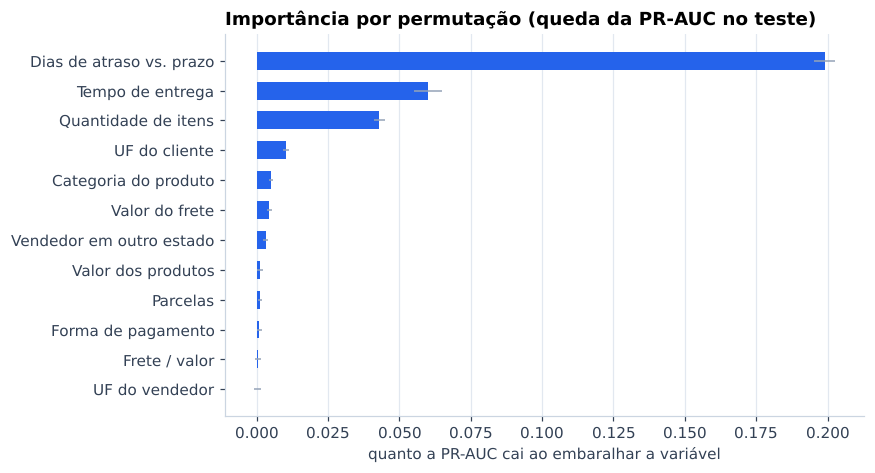

,variavel,queda_pr_auc,desvio
0,dias_atraso,0.1989,0.0038
1,tempo_entrega,0.0599,0.0050
5,qtd_itens,0.0430,0.0019
9,uf_cliente,0.0103,0.0010
8,categoria,0.0050,0.0007
3,valor_frete,0.0044,0.0009
7,estados_diferentes,0.0032,0.0009
2,valor_produtos,0.0012,0.0010
6,parcelas,0.0011,0.0006
11,pagamento,0.0009,0.0008


In [14]:
imp = permutation_importance(random_forest, X_teste, y_teste, scoring="average_precision",
                             n_repeats=5, random_state=SEMENTE, n_jobs=1)
importancia = pd.DataFrame({"variavel": FEATURES, "queda_pr_auc": imp.importances_mean,
                            "desvio": imp.importances_std}).sort_values("queda_pr_auc")

nomes_legiveis = {
    "dias_atraso": "Dias de atraso vs. prazo", "tempo_entrega": "Tempo de entrega",
    "valor_produtos": "Valor dos produtos", "valor_frete": "Valor do frete",
    "frete_sobre_valor": "Frete / valor", "qtd_itens": "Quantidade de itens",
    "parcelas": "Parcelas", "estados_diferentes": "Vendedor em outro estado",
    "categoria": "Categoria do produto", "uf_cliente": "UF do cliente",
    "uf_vendedor": "UF do vendedor", "pagamento": "Forma de pagamento",
}
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.barh([nomes_legiveis[v] for v in importancia["variavel"]], importancia["queda_pr_auc"],
        xerr=importancia["desvio"], color=AZUL, height=0.6, error_kw={"ecolor": CINZA, "lw": 1})
ax.set_title("Importância por permutação (queda da PR-AUC no teste)")
ax.set_xlabel("quanto a PR-AUC cai ao embaralhar a variável")
ax.grid(axis="y", visible=False)
salvar(fig, "11_importancia_variaveis.png")
plt.show()
importancia.sort_values("queda_pr_auc", ascending=False).round(4)

Para comparar, os maiores coeficientes da **Regressão Logística** (variáveis padronizadas: positivo aumenta a chance de nota negativa, negativo diminui):

In [15]:
nomes_colunas = baseline.named_steps["prep"].get_feature_names_out()
coef = pd.Series(baseline.named_steps["modelo"].coef_[0], index=nomes_colunas)
coef.reindex(coef.abs().sort_values(ascending=False).index).head(12).round(3).to_frame("coeficiente")

,coeficiente
num__tempo_entrega,0.703
cat__categoria_livros_interesse_geral,-0.545
cat__pagamento_boleto,-0.528
cat__uf_cliente_infrequent_sklearn,-0.461
cat__uf_vendedor_GO,-0.453
cat__uf_cliente_PB,-0.451
cat__pagamento_credit_card,-0.448
cat__uf_vendedor_BA,-0.405
cat__pagamento_debit_card,-0.401
cat__uf_cliente_RN,-0.382


**Leitura.** O **atraso domina**: embaralhar essa variável derruba a PR-AUC em cerca de 0,20. Depois vêm tempo de entrega (0,06) e quantidade de itens (0,04). UF do cliente, categoria e frete ajudam pouco; forma de pagamento, parcelas, frete/valor e UF do vendedor praticamente não contribuem. Isso confirma a EDA: a experiência de entrega é o que mais explica a nota negativa.

Na Regressão Logística os coeficientes ficam espalhados entre muitas categorias e o tempo de entrega aparece no lugar do atraso. Isso acontece porque as duas variáveis são muito correlacionadas, e o modelo linear não consegue representar o "degrau" no prazo.

## 9. Análise de erros

- **Falso negativo (FN):** o cliente deu nota 1 ou 2, mas o modelo não alertou. É o erro mais caro: um cliente insatisfeito sem contato.
- **Falso positivo (FP):** o modelo alertou, mas o cliente deu nota 3 a 5. Custa uma mensagem ou contato desnecessário.

Comparamos o perfil médio de cada grupo e lemos alguns comentários dos clientes. **O texto só é usado aqui, depois do modelo pronto, para entender os erros. Ele não entra no modelo.**

In [16]:
analise = base.loc[idx_teste].copy()
analise["prob"] = prob_rf
analise["previsto"] = (prob_rf >= threshold_rf).astype(int)
analise["grupo"] = np.select(
    [(analise.negativa == 1) & (analise.previsto == 1), (analise.negativa == 1) & (analise.previsto == 0),
     (analise.negativa == 0) & (analise.previsto == 1)], ["VP", "FN", "FP"], default="VN")

perfil = analise.groupby("grupo").agg(
    pedidos=("order_id", "size"), dias_atraso_mediana=("dias_atraso", "median"),
    perc_atrasados=("dias_atraso", lambda s: 100 * (s > 0).mean()),
    itens_media=("qtd_itens", "mean"), valor_mediana=("valor_produtos", "median"),
    frete_mediana=("valor_frete", "median"), perc_outro_estado=("estados_diferentes", lambda s: 100 * s.mean()),
    nota_media=("review_score", "mean"),
).reindex(["VP", "FN", "FP", "VN"])
perfil.round(1)

,pedidos,dias_atraso_mediana,perc_atrasados,itens_media,valor_mediana,frete_mediana,perc_outro_estado,nota_media
grupo,,,,,,,,
VP,1088,6.0,70.1,1.5,113.0,22.8,83.9,1.2
FN,1366,-12.0,1.8,1.2,85.9,17.2,60.7,1.3
FP,1290,-7.0,30.4,1.8,135.0,33.8,85.0,4.3
VN,15421,-13.0,0.7,1.1,79.9,16.6,61.6,4.6


In [17]:
textos = tabelas["reviews"].drop_duplicates("order_id", keep="last").set_index("order_id")["review_comment_message"]
analise["comentario"] = analise["order_id"].map(textos)

for g, titulo in [("FN", "Falsos negativos: insatisfeitos que o modelo NÃO alertou"),
                  ("FP", "Falsos positivos: alertas em clientes que deram nota 3 a 5")]:
    sub = analise[(analise.grupo == g) & analise.comentario.notna()]
    print(f"\n{titulo}")
    print(f"({100 * analise[analise.grupo == g].comentario.notna().mean():.0f}% deles deixaram comentário)")
    for _, r in sub.sample(8, random_state=SEMENTE).iterrows():
        print(f"  nota {r.review_score} | atraso {r.dias_atraso:+d} dias | prob {100 * r.prob:.0f}% | {str(r.comentario)[:110]}")


Falsos negativos: insatisfeitos que o modelo NÃO alertou
(75% deles deixaram comentário)
  nota 2 | atraso -6 dias | prob 12% | Demora demasiada na entrega
  nota 1 | atraso -15 dias | prob 8% | O controle remoto do play 2 não é Sonic como anunciado, não veio o suporte pra deixar o aparelho em pé como na
  nota 1 | atraso -8 dias | prob 9% | Película veio quebrada,comprei pela Lojas lannister.E agora é o parceiro que é responsável? 
Comprei pela loj
  nota 2 | atraso -3 dias | prob 9% | No dia 6/8 recebi o produto. Como era diferente do tamanho solicitado e a qualidade abaixo da esperada solicit
  nota 1 | atraso -15 dias | prob 7% | E muito desordenado comprei três produtos mais não veio no dia sertões veio separado e em data separada 
  nota 1 | atraso -4 dias | prob 15% | Recebi apenas um de dois que comprei. Um lixo. Já abri chamado no stark para cancelar a entrega do outro e est
  nota 2 | atraso -6 dias | prob 9% | Era um jogo de cama 4 peças e veio de3 pecas
  nota 1 | atraso -

In [18]:
# Palavras frequentes nos comentários dos falsos negativos (sinal de problemas que os dados não mostram)
termos = {"produto errado/diferente": r"errad|diferente|outro produto",
          "faltou item / veio incompleto": r"falt|incomplet|apenas um|só (?:veio|recebi) um|somente um",
          "defeito / quebrado / qualidade": r"defeit|quebrad|qualidade|danific|não funciona|nao funciona",
          "não recebi": r"não recebi|nao recebi|não chegou|nao chegou"}
fn_txt = analise.loc[(analise.grupo == "FN") & analise.comentario.notna(), "comentario"].str.lower()
pd.Series({t: 100 * fn_txt.str.contains(p, regex=True).mean() for t, p in termos.items()}, name="% dos FN com comentário").round(1).to_frame()

,% dos FN com comentário
produto errado/diferente,10.8
faltou item / veio incompleto,9.0
defeito / quebrado / qualidade,15.0
não recebi,9.5


**Leitura.** Os **falsos negativos** são quase todos pedidos entregues no prazo (só 1,8% atrasados, mediana de 12 dias adiantados). Para o modelo, parecem pedidos normais. Os comentários mostram o motivo: defeito ou qualidade (15%), produto errado ou diferente (11%), item faltando (9%) e até "não recebi" em pedidos marcados como entregues (9,5%). São problemas que **não aparecem nos dados disponíveis antes da avaliação**.

Os **falsos positivos** são pedidos com perfil de risco (30% atrasados, mais itens, frete maior, 85% com vendedor em outro estado) em que o cliente foi tolerante, alguns até dando nota 5. Para o atendimento, um falso positivo custa pouco (um contato a mais). O falso negativo é o cliente insatisfeito que escapa.

### 9.1 Recorte: clientes que avaliaram antes de receber

No notebook 01 vimos que cerca de 5% dos clientes avaliaram **antes** da entrega, com muita nota negativa. Medimos o desempenho com e sem esse grupo, para não superestimar o modelo:

In [19]:
linhas = {}
for nome, mascara in [("todos os pedidos de teste", np.ones(len(analise), bool)),
                      ("só quem avaliou depois da entrega", analise.avaliou_antes_entrega.values == 0)]:
    sub = analise[mascara]
    linhas[nome] = metricas(sub.negativa, sub.prob.values, threshold_rf)
pd.DataFrame(linhas).T[["recall", "precisao", "f1", "roc_auc", "pr_auc"]].round(3)

,recall,precisao,f1,roc_auc,pr_auc
todos os pedidos de teste,0.443,0.458,0.450,0.759,0.461
só quem avaliou depois da entrega,0.214,0.264,0.236,0.672,0.188


**Leitura.** Este é o ponto mais importante da discussão. Sem os clientes que avaliaram antes de receber, o desempenho **cai bastante**: recall 0,21, PR-AUC 0,19 e ROC-AUC 0,67. Ainda é o dobro de um chute (a taxa de negativas nesse grupo é 9,5%), mas fica longe do resultado geral. Ou seja, boa parte do acerto do modelo vem de pedidos atrasados em que o cliente reclamou enquanto esperava.

Conclusão prática: o modelo é mais útil **durante o atraso** (assim que o prazo vence) do que depois de uma entrega no prazo. Quando a entrega é no prazo, a nota negativa depende principalmente do produto, e isso os dados não mostram.

### 9.2 Checagem extra: o modelo funciona em pedidos mais recentes?

A divisão principal é aleatória (estratificada). Como os dados são de 2016 a 2018, testamos também uma **divisão temporal**: treino com os 80% pedidos mais antigos e teste com os 20% mais recentes. Se o desempenho cair muito, o comportamento mudou com o tempo.

In [20]:
ordem = base.sort_values("order_purchase_timestamp")
corte = int(0.8 * len(ordem))
antigos, recentes = ordem.iloc[:corte], ordem.iloc[corte:]
rf_temporal = sklearn.base.clone(random_forest).fit(antigos[FEATURES], antigos[ALVO])
p_temp = rf_temporal.predict_proba(recentes[FEATURES])[:, 1]
print(f"Treino até {antigos.order_purchase_timestamp.max():%d/%m/%Y}, teste de {recentes.order_purchase_timestamp.min():%d/%m/%Y} a {recentes.order_purchase_timestamp.max():%d/%m/%Y}")
print(f"ROC-AUC temporal: {roc_auc_score(recentes[ALVO], p_temp):.3f} (aleatória: {m_rf['roc_auc']:.3f})")
print(f"PR-AUC temporal:  {average_precision_score(recentes[ALVO], p_temp):.3f} (aleatória: {m_rf['pr_auc']:.3f})")
print(f"Taxa de negativas no período recente: {100 * recentes[ALVO].mean():.1f}%")
temporal = {"roc_auc": roc_auc_score(recentes[ALVO], p_temp), "pr_auc": average_precision_score(recentes[ALVO], p_temp)}

Treino até 27/05/2018, teste de 27/05/2018 a 29/08/2018
ROC-AUC temporal: 0.682 (aleatória: 0.759)
PR-AUC temporal:  0.293 (aleatória: 0.461)
Taxa de negativas no período recente: 9.7%


**Leitura.** Em pedidos mais recentes o desempenho cai (ROC-AUC 0,68 contra 0,76; PR-AUC 0,29 contra 0,46). Conferimos o motivo: no período recente só 3,4% dos pedidos atrasaram (contra 7,5% antes), e os atrasados geraram menos notas negativas (47% contra 64%). Com menos atrasos, sobra menos do sinal que o modelo mais usa. Em uso real, o modelo precisaria ser **retreinado periodicamente** e ter o desempenho acompanhado.

## 10. Salvando o modelo e as métricas para o app

- `models/modelo.joblib`: o `Pipeline` completo (pré-processamento + Random Forest), treinado no conjunto de treino. É o mesmo modelo avaliado acima.
- `models/metricas.json`: números exibidos na página "Sobre o modelo". **O app lê daqui; nada é digitado à mão.**
- `models/referencia.json`: valores de apoio do app (taxa base, lista de categorias, prazo mediano por UF, pedido típico usado na explicação).

In [21]:
ARQ_MODELO.parent.mkdir(exist_ok=True)
joblib.dump(random_forest, ARQ_MODELO, compress=3)
print(f"Tamanho do modelo: {ARQ_MODELO.stat().st_size / 1e6:.1f} MB")

treino = base.loc[X_treino.index]
contagem_cat = treino["categoria"].value_counts()
referencia = {
    "taxa_base": float(y_treino.mean()),
    "threshold": threshold_rf,
    "categorias": contagem_cat[contagem_cat >= MIN_PEDIDOS_CATEGORIA].index.tolist(),
    "prazo_mediano_por_uf": treino.groupby("uf_cliente")["prazo_estimado"].median().to_dict(),
    "prazo_mediano_geral": float(treino["prazo_estimado"].median()),
    "parcelas_mediana_por_pagamento": treino.groupby("pagamento")["parcelas"].median().astype(int).to_dict(),
    "pedido_tipico": {
        "categoria": treino["categoria"].mode()[0],
        "valor_produtos": round(float(treino["valor_produtos"].median()), 2),
        "valor_frete": round(float(treino["valor_frete"].median()), 2),
        "qtd_itens": int(treino["qtd_itens"].median()),
        "pagamento": treino["pagamento"].mode()[0],
        "uf_vendedor": treino["uf_vendedor"].mode()[0],
        "uf_cliente": treino["uf_cliente"].mode()[0],
        "dias_atraso": int(treino["dias_atraso"].median()),
    },
    "versao_sklearn": sklearn.__version__,
}
with open(ARQ_REFERENCIA, "w", encoding="utf-8") as f:
    json.dump(referencia, f, ensure_ascii=False, indent=2)

def arred(d):
    return {k: round(float(v), 4) for k, v in d.items()}

metricas_json = {
    "gerado_em": date.today().isoformat(),
    "modelo_final": "Random Forest",
    "baseline": "Regressão Logística",
    "parametros_modelo": {"n_estimators": 200, "max_features": "sqrt", "min_samples_leaf": escolhido},
    "periodo": {"inicio": f"{base.order_purchase_timestamp.min():%m/%Y}", "fim": f"{base.order_purchase_timestamp.max():%m/%Y}"},
    "n_pedidos": int(len(base)), "n_treino": int(len(X_treino)), "n_teste": int(len(X_teste)),
    "taxa_base": round(float(y.mean()), 4),
    "divisao": "estratificada 80/20",
    "k_folds": 5,
    "criterio_threshold": "maior F1 na validação cruzada do treino",
    "threshold": round(threshold_rf, 4),
    "threshold_baseline": round(threshold_lr, 4),
    "validacao_cruzada": {"random_forest": {"roc_auc": round(tabela_cv.loc["Random Forest", "_roc"], 4), "pr_auc": round(tabela_cv.loc["Random Forest", "_pr"], 4)},
                          "baseline": {"roc_auc": round(tabela_cv.loc["Regressão Logística (baseline)", "_roc"], 4), "pr_auc": round(tabela_cv.loc["Regressão Logística (baseline)", "_pr"], 4)}},
    "teste": {"random_forest": arred(m_rf), "baseline": arred(m_lr), "ingenuo": arred(m_ing)},
    "matriz_confusao": {"vn": int(vn), "fp": int(fp), "fn": int(fn), "vp": int(vp)},
    "faixas": [{"faixa": idx, "perc_pedidos": round(float(r.perc_pedidos), 1), "taxa_real": round(float(r.taxa_real), 1)}
               for idx, r in tabela_faixas.iterrows()],
    "importancia": [{"variavel": nomes_legiveis[r.variavel], "queda_pr_auc": round(float(r.queda_pr_auc), 4)}
                    for r in importancia.sort_values("queda_pr_auc", ascending=False).itertuples()],
    "temporal": arred(temporal),
}
with open(ARQ_METRICAS, "w", encoding="utf-8") as f:
    json.dump(metricas_json, f, ensure_ascii=False, indent=2)
print(json.dumps(metricas_json["teste"]["random_forest"], indent=2))

Tamanho do modelo: 2.4 MB


{
  "recall": 0.4434,
  "precisao": 0.4575,
  "f1": 0.4503,
  "roc_auc": 0.759,
  "pr_auc": 0.4607,
  "acuracia": 0.8614,
  "threshold": 0.2155,
  "perc_alertas": 0.1241
}


## 11. Demonstração: uma nova entrada produz um resultado compreensível

As mesmas funções usadas pelo app e pelo script `python -m src.prever`.

In [22]:
from src.explicacao import explicar
from src.config import faixa_risco

exemplos = {
    "Pedido no prazo": dict(categoria="cama_mesa_banho", valor_produtos=90, valor_frete=15, qtd_itens=1,
                            pagamento="credit_card", uf_vendedor="SP", uf_cliente="SP", dias_atraso=-10),
    "Atraso longo": dict(categoria="moveis_decoracao", valor_produtos=180, valor_frete=45, qtd_itens=1,
                         pagamento="boleto", uf_vendedor="SP", uf_cliente="BA", dias_atraso=15),
    "Vários itens, outro estado": dict(categoria="informatica_acessorios", valor_produtos=250, valor_frete=60, qtd_itens=3,
                                       pagamento="credit_card", uf_vendedor="SP", uf_cliente="RJ", dias_atraso=0),
}
modelo_salvo = joblib.load(ARQ_MODELO)
for nome, entrada in exemplos.items():
    p, fatores = explicar(modelo_salvo, entrada, referencia)
    faixa, _, acao = faixa_risco(p)
    print(f"\n{nome}: {100 * p:.0f}% ({faixa}). {acao}")
    for f in fatores:
        print(f"   {f['pp']:+6.1f} p.p.  {f['rotulo']}")


Pedido no prazo: 9% (Risco baixo). Seguir o fluxo normal de atendimento.
     +0.3 p.p.  Entrega 10 dias adiantado (típico: 12 dias adiantado)
     -0.1 p.p.  Valor dos produtos R$ 90



Atraso longo: 63% (Risco muito alto). Priorizar na fila do atendimento e oferecer compensação, como cupom ou frete grátis.
    +51.6 p.p.  Entrega 15 dias atrasado (típico: 12 dias adiantado)
     -2.6 p.p.  Pagamento: Boleto
     +1.8 p.p.  Cliente em BA
     +1.0 p.p.  Valor dos produtos R$ 180
     +1.0 p.p.  Categoria: Móveis e decoração



Vários itens, outro estado: 32% (Risco alto). Contato do atendimento antes da avaliação, explicando o atraso ou o problema.
    +13.6 p.p.  3 itens no pedido
     +6.6 p.p.  Frete R$ 60 (24% do valor)
     +6.3 p.p.  Cliente em RJ
     +5.0 p.p.  Entrega no prazo (típico: 12 dias adiantado)
     +2.4 p.p.  Valor dos produtos R$ 250
     +0.1 p.p.  Categoria: Informática e acessórios


## 12. Conclusões

- A **Random Forest supera o baseline** em todas as métricas (teste: F1 0,450 contra 0,416; PR-AUC 0,461 contra 0,395; ROC-AUC 0,759 contra 0,736).
- Com threshold de 22%, o modelo alerta cerca de 12% dos pedidos e encontra **44% dos clientes insatisfeitos**, com precisão de 46%. Alertar ao acaso a mesma quantidade encontraria só 12%.
- As probabilidades são bem calibradas, e as faixas de risco do app (15%, 30% e 50%) separam bem os pedidos.
- O **atraso** é o fator dominante. O modelo é mais útil para acionar o atendimento **assim que o prazo vence**.
- **Limitações:** problemas de produto (defeito, item errado ou faltando) não aparecem nos dados e geram a maioria dos falsos negativos. Sem os clientes que avaliaram antes de receber, o desempenho cai bastante. Em pedidos mais recentes, com menos atrasos, o desempenho também cai, então o modelo precisaria ser retreinado com frequência.